# Predicting when LLMs get it wrong — walkthrough

**Research question.** Can simple features from an LLM response help predict whether the answer is correct or unreliable?

**Hypothesis.** A combination of response length, consistency, confidence cues and self-check behaviour predicts errors better than chance.

This notebook walks through the five stages of the pipeline, one cell at a time:

| # | Stage | Module |
|---|---|---|
| 1 | Questions with known answers (GSM8K) | `llm_reliability.data` |
| 2 | Responses from an LLM, labelled correct / wrong | `collect`, `grading` |
| 3 | Features extracted from each response | `features` |
| 4 | Classifiers + baselines | `models` |
| 5 | Evaluation: metrics, significance tests, feature importance | `evaluate`, `plots`, `report` |

By default it uses `configs/demo.yaml`, which runs the **offline simulated LLM** so the notebook works without an API key. Change `CONFIG` below to `configs/claude.yaml` or `configs/ollama.yaml` (after collecting responses) to analyse a real model — every cell works the same way.

In [1]:
import logging

import pandas as pd
from IPython.display import Image, Markdown, display

from llm_reliability import pipeline
from llm_reliability.config import load_config
from llm_reliability.features import FEATURE_DESCRIPTIONS, FEATURE_GROUPS, text_features
from llm_reliability.grading import extract_answer

logging.basicConfig(level=logging.WARNING)
pd.set_option("display.max_colwidth", 120)

CONFIG = "configs/demo.yaml"
cfg = load_config(CONFIG)
print(f"run: {cfg.run_name}   provider: {cfg.llm.provider}   model: {cfg.llm.model}")

run: demo   provider: simulated   model: simulated-llm


## Stage 1 — Questions

GSM8K is a set of grade-school math word problems. Every answer is a single number, so we can grade the model automatically and objectively. We also record how many reasoning steps the reference solution needs, a rough measure of difficulty.

In [2]:
questions = pipeline.load_questions(cfg)
q = questions[0]
print(f"{len(questions)} questions loaded\n")
print("QUESTION:", q.question)
print("GOLD ANSWER:", q.gold_answer, "   steps in reference solution:", q.n_steps)
pd.Series([x.n_steps for x in questions]).value_counts().sort_index().rename("questions by n_steps").to_frame().T

1000 questions loaded

QUESTION: Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?
GOLD ANSWER: 18    steps in reference solution: 2


,2,3,4,5,6,7,8,9,11
questions by n_steps,248,290,222,131,63,30,14,1,1


## Stage 2 — Responses

For each question the pipeline makes:
* one **main answer** (the one we judge),
* `n_samples` **extra answers** to the same prompt (to measure consistency),
* one **self-check** call, where the model grades its own main answer.

Everything is saved to `runs/<run_name>/responses.jsonl`. Collection is resumable: re-running only queries questions that are missing, so this cell is instant once responses exist.

In [3]:
records = pipeline.stage_collect(cfg)
rec = records[0]
print("MAIN RESPONSE:\n" + rec["response"]["text"])
print("\nEXTRA SAMPLE #1:\n" + rec["samples"][0]["text"] if rec["samples"] else "")
print("\nSELF-CHECK:\n" + (rec["self_check"]["text"] if rec["self_check"] else "(disabled)"))

MAIN RESPONSE:
Janet sells 16 - 3 - 4 = 9 duck eggs a day.
Definitely, she makes 9 * 2 = $18 every day at the farmer’s market.
Answer: 18

EXTRA SAMPLE #1:
Janet sells 16 - 3 - 4 = 9 duck eggs a day.
Clearly, she makes 9 * 2 = $18 every day at the farmer’s market.
Wait, let me re-check that step.
Answer: 18

SELF-CHECK:
Verdict: CORRECT
Confidence: 100


### Labelling correctness

We pull the final number out of the response (preferring the requested `Answer: <number>` line) and compare it to the gold answer. The label is **`is_wrong` = 1** when they differ — "wrong" is the positive class because we want to *flag* errors.

In [4]:
pred, how = extract_answer(rec["response"]["text"])
print(f"extracted answer: {pred} (found via: {how}),  gold: {rec['gold_answer']}")

extracted answer: 18.0 (found via: explicit),  gold: 18


## Stage 3 — Features

Features come in five groups. The first three need only the single response (they are free); the last two need extra LLM calls.

In [5]:
rows = [(g, f, FEATURE_DESCRIPTIONS[f]) for g, fs in FEATURE_GROUPS.items() for f in fs]
pd.DataFrame(rows, columns=["group", "feature", "meaning"])

,group,feature,meaning
0,length,n_chars,Characters in the response
1,length,n_words,Words in the response
2,length,n_sentences,Sentences in the response
3,length,n_lines,"Non-empty lines (roughly, reasoning steps)"
4,length,n_numbers,Numbers written in the response
5,length,n_output_tokens,Output tokens billed by the API (includes hidden reasoning tokens)
6,confidence_language,hedge_count,"Hedging phrases ('I think', 'probably', ...)"
7,confidence_language,hedge_rate,Hedging phrases per 100 words
8,confidence_language,confident_count,"Certainty phrases ('clearly', 'definitely', ...)"
9,confidence_language,confident_rate,Certainty phrases per 100 words


In [6]:
# Features of one made-up response, to see them in action:
pd.Series(text_features("I think the total is probably 12. Wait, let me re-check: 5 + 8 = 13.\nAnswer: 13")).to_frame("value").T

,n_chars,n_words,n_sentences,n_lines,n_numbers,hedge_count,hedge_rate,confident_count,confident_rate,self_correction_count,answer_explicit,answer_missing,answer_is_integer,answer_log_magnitude
value,79.0,18.0,3.0,2.0,5.0,2.0,11.111111,0.0,0.0,2.0,1.0,0.0,1.0,1.146128


In [7]:
df = pipeline.stage_features(cfg)
print(f"{len(df)} questions, model error rate = {df.is_wrong.mean():.1%}")
df.groupby("is_wrong")[["n_words", "hedge_rate", "agreement_rate", "selfcheck_confidence"]].mean().rename(index={0: "correct", 1: "wrong"})

1000 questions, model error rate = 25.5%

,n_words,hedge_rate,agreement_rate,selfcheck_confidence
is_wrong,,,,
correct,61.789262,0.417516,0.799195,0.807772
wrong,83.639216,0.522434,0.199216,0.553804


## Stages 4 & 5 — Classifiers and evaluation

* 25% of questions are held out as a **test set** and not touched until the end.
* Three classifiers (logistic regression, random forest, gradient boosting) are trained twice: on **simple** (free) features and on **combined** features.
* They are compared with **baselines**: always-majority, random guessing, and tuned single-feature rules.
* The best model in each feature set is picked by **cross-validation on the training set** (never by test score).
* Test metrics come with **95% bootstrap confidence intervals**; "better than chance" is checked with a **permutation test**.

In [8]:
results, report_path = pipeline.stage_evaluate(cfg, df)
cols = ["name", "kind", "roc_auc", "roc_auc_ci_low", "roc_auc_ci_high", "precision_wrong", "recall_wrong", "f1_wrong", "accuracy"]
results.test_metrics[cols].round(3)

,name,kind,roc_auc,roc_auc_ci_low,roc_auc_ci_high,precision_wrong,recall_wrong,f1_wrong,accuracy
0,majority,baseline,0.500,0.500,0.500,0.000,0.000,0.000,0.744
1,random,baseline,0.506,0.448,0.568,0.266,0.266,0.266,0.624
2,rule:agreement_rate,baseline,0.924,0.881,0.962,0.705,0.859,0.775,0.872
3,rule:selfcheck_says_incorrect,baseline,0.730,0.667,0.798,0.655,0.562,0.605,0.812
4,rule:selfcheck_confidence,baseline,0.793,0.723,0.861,0.627,0.578,0.602,0.804
5,rule:hedge_rate,baseline,0.568,0.500,0.639,0.256,1.000,0.408,0.256
6,rule:n_words,baseline,0.680,0.608,0.757,0.374,0.625,0.468,0.636
7,simple:logistic_regression,simple,0.771,0.703,0.840,0.511,0.703,0.592,0.752
8,simple:random_forest,simple,0.763,0.697,0.828,0.523,0.359,0.426,0.752
9,simple:gradient_boosting,simple,0.730,0.663,0.799,0.438,0.500,0.467,0.708


In [9]:
h = results.hypotheses
lines = [
    f"- **Combined features better than chance?** test AUC = {h['combined_better_than_chance']['auc']:.3f}, permutation p = {h['combined_better_than_chance']['p_value']:.4f}",
    f"- **Simple (free) features better than chance?** test AUC = {h['simple_better_than_chance']['auc']:.3f}, p = {h['simple_better_than_chance']['p_value']:.4f}",
    f"- **Combined vs. simple:** AUC difference {h['combined_vs_simple']['auc_difference']:+.3f} (95% CI {h['combined_vs_simple']['ci_low']:+.3f} to {h['combined_vs_simple']['ci_high']:+.3f})",
]
if "combined_vs_best_rule" in h:
    r = h["combined_vs_best_rule"]
    lines.append(f"- **Combined vs. best single rule ({h['best_models']['rule']}):** {r['auc_difference']:+.3f} (95% CI {r['ci_low']:+.3f} to {r['ci_high']:+.3f})")
display(Markdown("\n".join(lines)))

- **Combined features better than chance?** test AUC = 0.959, permutation p = 0.0010
- **Simple (free) features better than chance?** test AUC = 0.771, p = 0.0010
- **Combined vs. simple:** AUC difference +0.187 (95% CI +0.121 to +0.253)
- **Combined vs. best single rule (rule:agreement_rate):** +0.035 (95% CI +0.005 to +0.070)

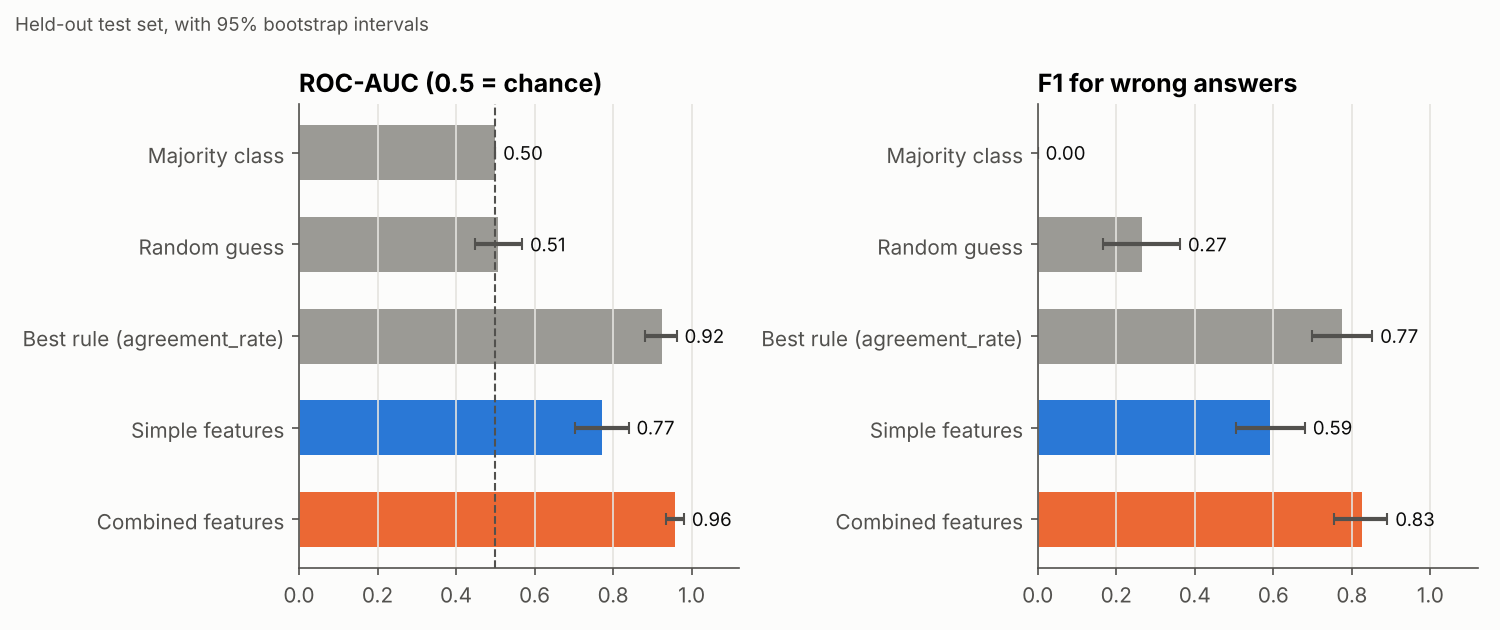

In [10]:
display(Image(filename=str(cfg.figures_dir / "model_comparison.png")))

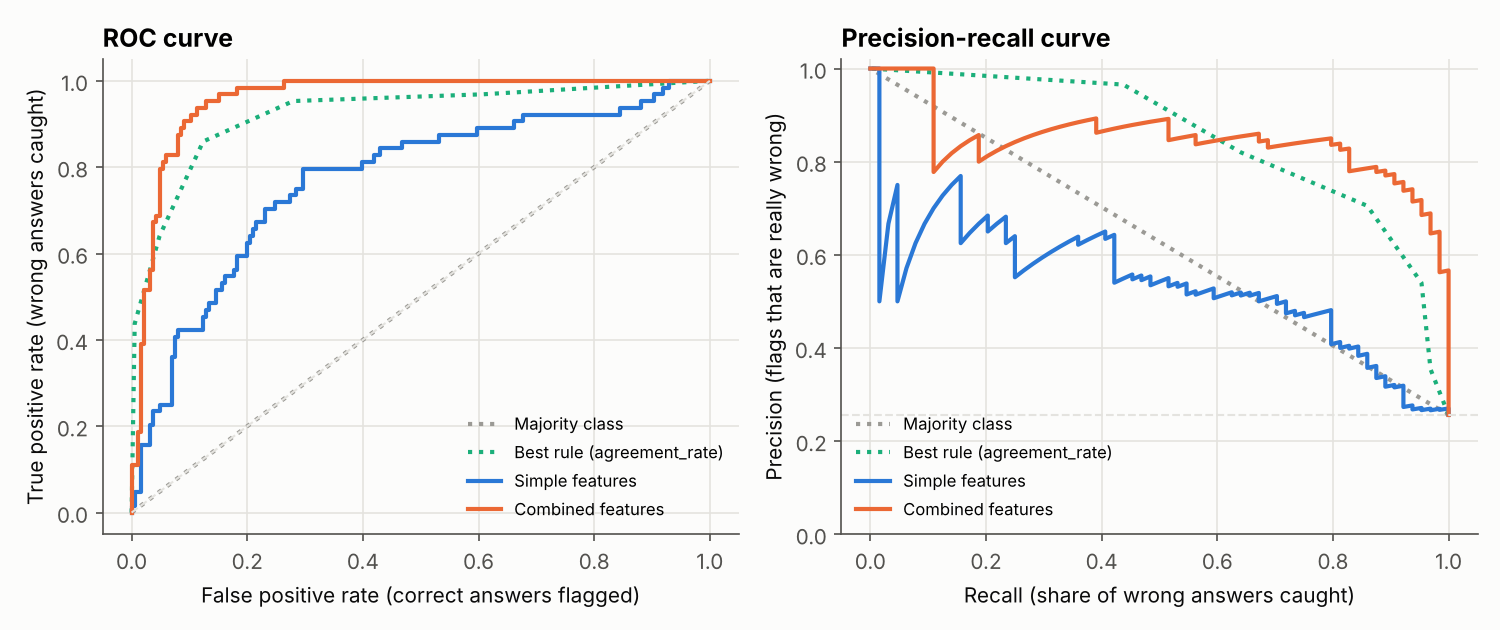

In [11]:
display(Image(filename=str(cfg.figures_dir / "roc_pr_curves.png")))

### Which signals matter?

*Permutation importance*: shuffle one feature on the test set and see how much the AUC drops. *Ablation*: retrain with only one group, or with one group removed.

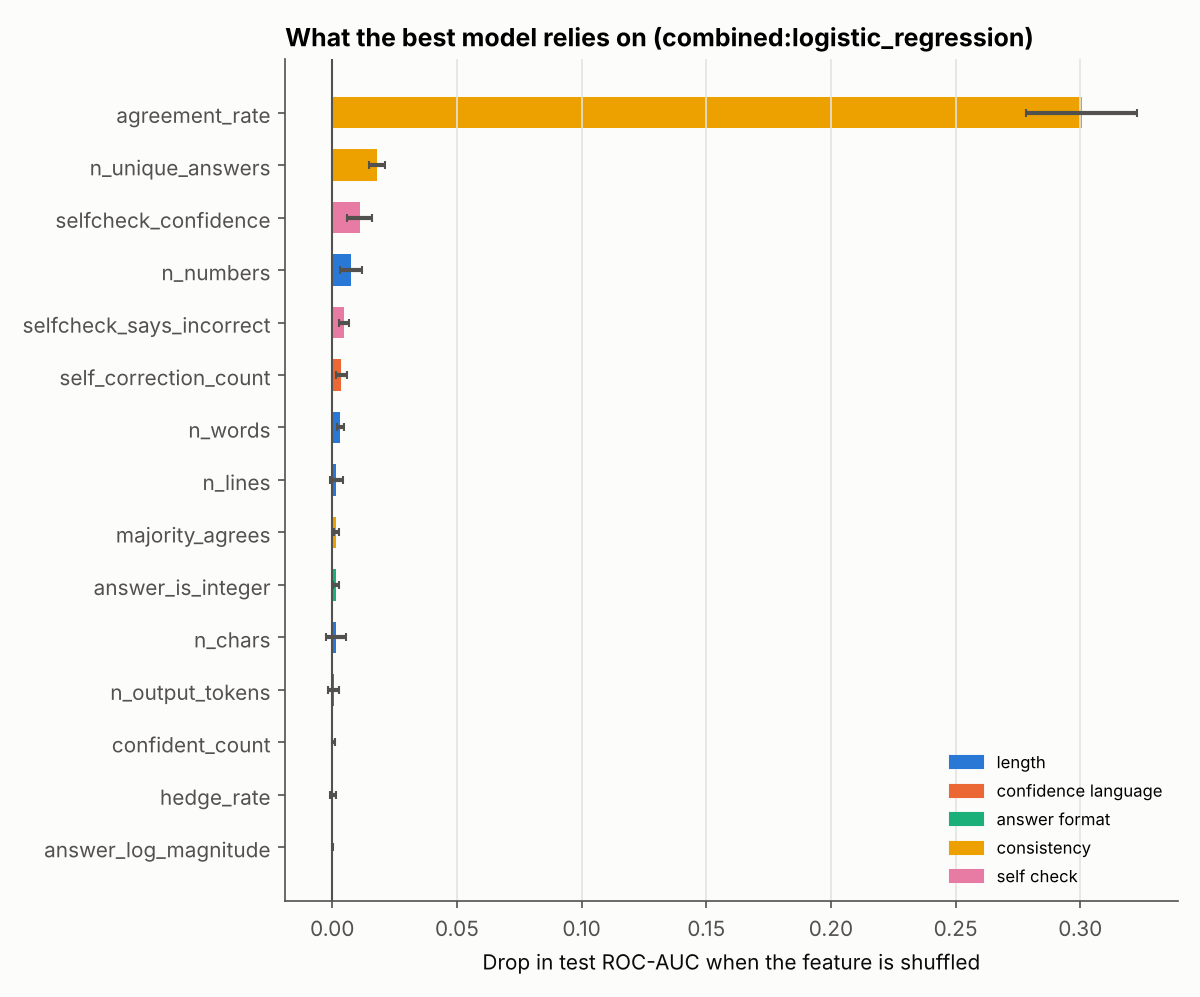

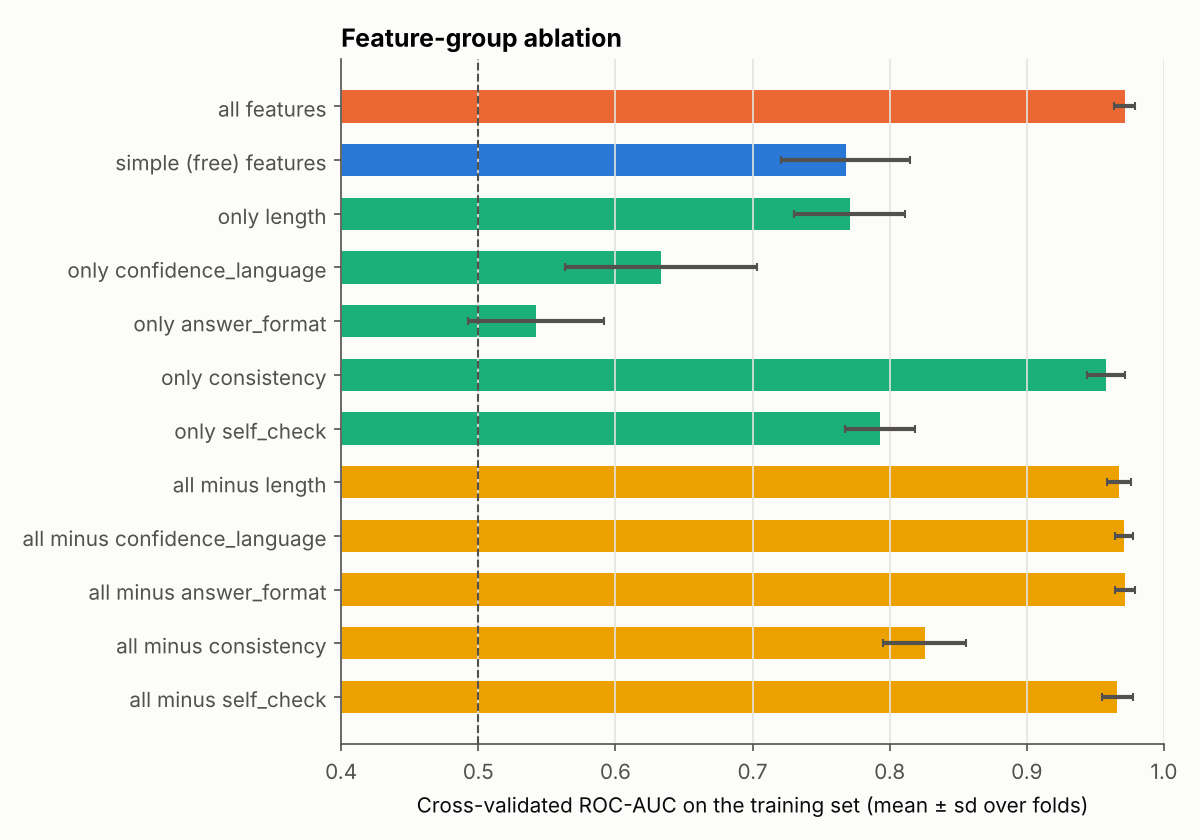

In [12]:
display(Image(filename=str(cfg.figures_dir / "feature_importance.png")))
display(Image(filename=str(cfg.figures_dir / "ablation.png")))

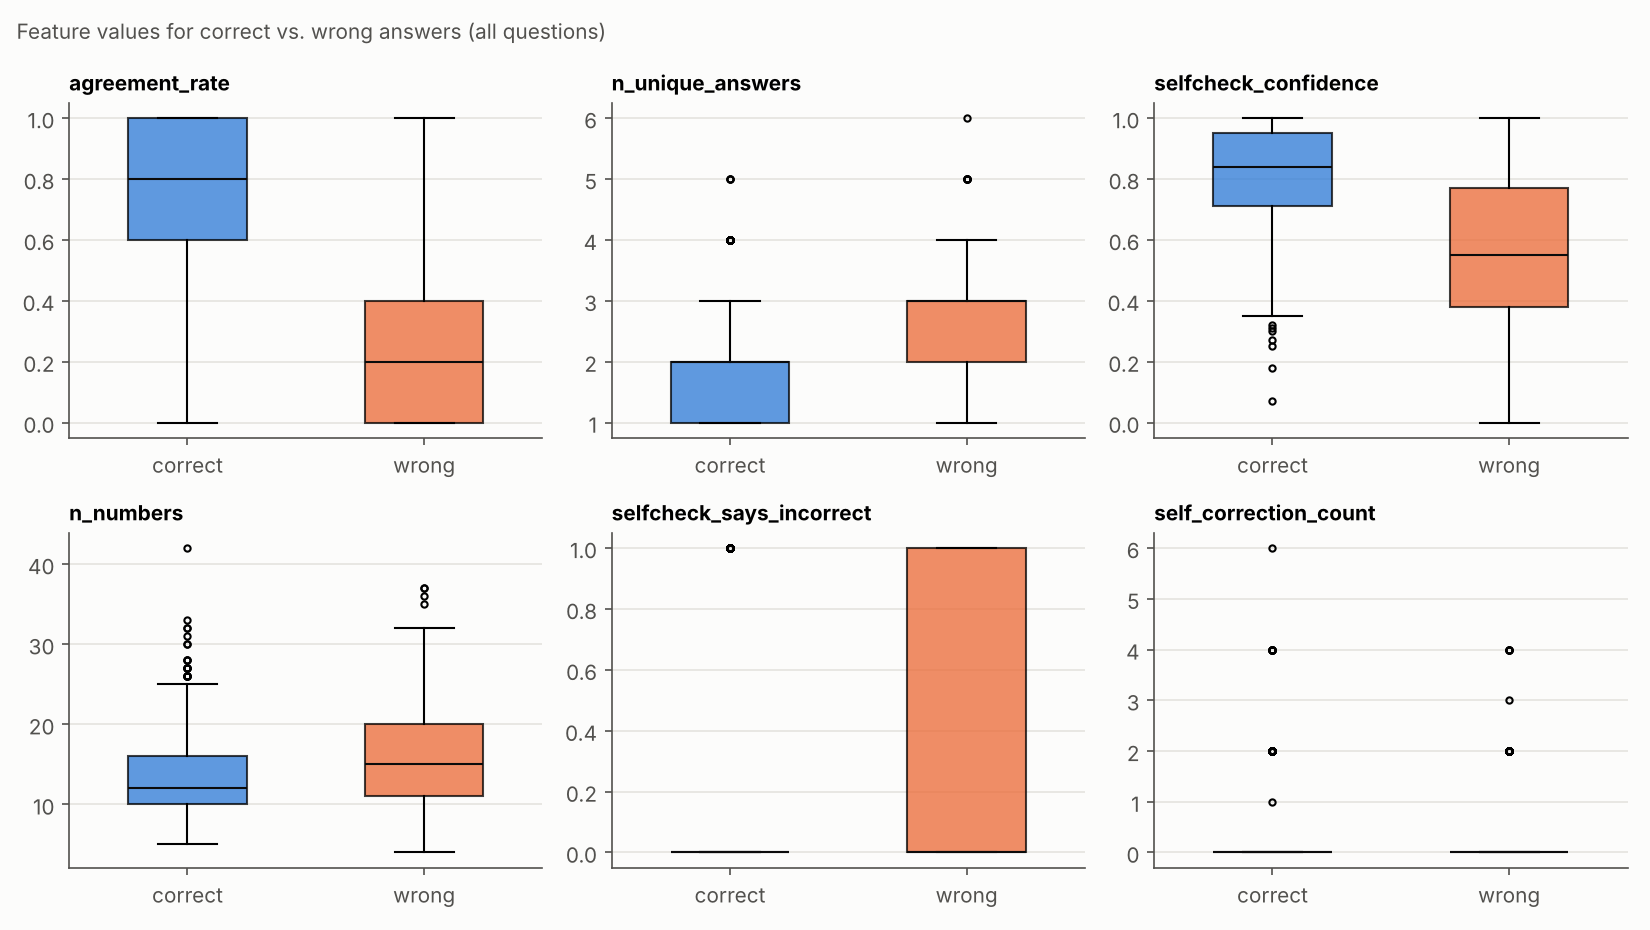

In [13]:
display(Image(filename=str(cfg.figures_dir / "feature_distributions.png")))

## Reading the results honestly

* With the **demo config the data is simulated**: the fake LLM was built so that uncertainty leaks into its responses, so strong results here are expected and prove nothing about real models. They only prove the pipeline works.
* For the real study, collect responses from a real model (`llmrel run --config configs/claude.yaml` or `configs/ollama.yaml`), set `CONFIG` above to that file and re-run this notebook.
* Look at the **confidence intervals**, not just the point estimates. If an interval for the AUC difference includes 0, the data cannot tell the two approaches apart.
* A null result ("these features don't predict errors better than chance") is a valid, reportable answer to the research question.

The full Markdown report for this run is written to `runs/<run_name>/report.md`.

In [14]:
print(report_path)

/home/user/predicting-llm-errors/runs/demo/report.md
